# Chapter 16: Functions Are Relationships

*Math Class Didn't Show Its Work* by Jason Karpeles

In this notebook you will test whether a relationship gives each input exactly one output, learn what a fractional exponent such as 2/3 asks you to do, spot a quadratic pattern from a table by taking differences twice, and tell linear, quadratic and exponential patterns apart.

**A note on the code.** The code cells are optional reading. Every result and every picture is shown right below the cell that makes it, so you can follow along without running anything. If you do want to experiment, change a number in a cell and run it again.

## Setup

This one cell loads two common tools, numpy (for lists of numbers) and matplotlib (for pictures), and a few small helpers that tidy the output.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
%matplotlib inline

TEAL, NAVY, GOLD, RED, GREY = "#0f6268", "#172a3b", "#b8860b", "#b5472f", "#8a949a"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def finish(fig):
    """Tidy the layout and show the picture."""
    fig.tight_layout()
    plt.show()

def q(v):
    """Write a Fraction the way we would by hand: 3/2, or 5 when whole."""
    v = Fraction(v)
    return str(v.numerator) if v.denominator == 1 else f"{v.numerator}/{v.denominator}"

def par(v):
    """Wrap negative numbers in parentheses, the way we do when substituting."""
    s = q(v)
    return f"({s})" if Fraction(v) < 0 else s

## 1. Exactly one output

**The question:** Which of these relationships keep the promise of one output for each input?

**The equations from the chapter:**

$$y^2 = x \qquad\qquad y = x^2$$

**What the symbols mean:** Inputs sit on the left and outputs on the right. Each arrow is one assignment. A *function* gives every allowed input exactly one arrow.

Predict first: Panel B sends two different inputs to 4. Is it still a function?

In [2]:
relations = {
    "Panel A": [(1, 10), (2, 20), (3, 30)],
    "Panel B": [(-2, 4), (0, 0), (2, 4)],
    "Panel C": [(1, 5), (1, 6), (2, 7)],
    "y^2 = x on inputs 0, 1, 4": [(0, 0), (1, 1), (1, -1), (4, 2), (4, -2)],
}
for name, pairs in relations.items():
    ins = sorted({a for a, _ in pairs})
    counts = [sum(1 for a, _ in pairs if a == i) for i in ins]
    arrows = "; ".join(f"{i} to {', '.join(str(b) for a, b in pairs if a == i)}" for i in ins)
    two = [i for i, c in zip(ins, counts) if c > 1]
    print(f"{name}")
    print(f"  arrows: {arrows}")
    print(f"  count the arrows leaving each input: {' + '.join(map(str, counts))} = {len(pairs)} arrows for {len(ins)} inputs")
    print(f"  inputs with two outputs: {two if two else 'none'}  ->  function? {'yes' if not two else 'no'}")
    print()
print("Panel B in words: (-2)^2 = 4 and 2^2 = 4, so two inputs share the output 4.")
print("That is allowed. Each input still has exactly one arrow.")
print("For y^2 = x at input 4: 2^2 = 4 and (-2)^2 = 4, so y = 2 and y = -2 both fit. Input 4 has two outputs.")
print()
print("Check: y = x^2 on inputs -1, 0, 1:  (-1)^2 = 1,  0^2 = 0,  1^2 = 1  -> one output each, so yes, a function.")

Panel A
  arrows: 1 to 10; 2 to 20; 3 to 30
  count the arrows leaving each input: 1 + 1 + 1 = 3 arrows for 3 inputs
  inputs with two outputs: none  ->  function? yes

Panel B
  arrows: -2 to 4; 0 to 0; 2 to 4
  count the arrows leaving each input: 1 + 1 + 1 = 3 arrows for 3 inputs
  inputs with two outputs: none  ->  function? yes

Panel C
  arrows: 1 to 5, 6; 2 to 7
  count the arrows leaving each input: 2 + 1 = 3 arrows for 2 inputs
  inputs with two outputs: [1]  ->  function? no

y^2 = x on inputs 0, 1, 4
  arrows: 0 to 0; 1 to 1, -1; 4 to 2, -2
  count the arrows leaving each input: 1 + 2 + 2 = 5 arrows for 3 inputs
  inputs with two outputs: [1, 4]  ->  function? no

Panel B in words: (-2)^2 = 4 and 2^2 = 4, so two inputs share the output 4.
That is allowed. Each input still has exactly one arrow.
For y^2 = x at input 4: 2^2 = 4 and (-2)^2 = 4, so y = 2 and y = -2 both fit. Input 4 has two outputs.

Check: y = x^2 on inputs -1, 0, 1:  (-1)^2 = 1,  0^2 = 0,  1^2 = 1  -> one outp

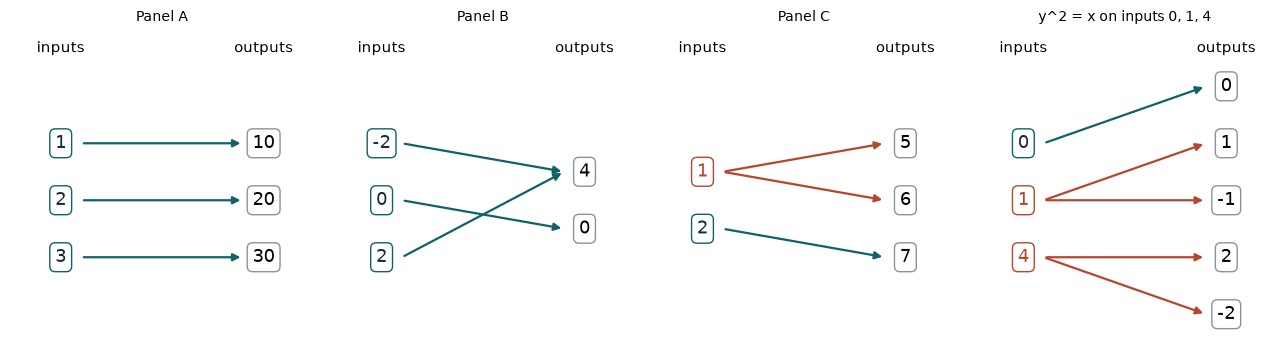

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, pairs) in zip(axes, relations.items()):
    ins = sorted({a for a, _ in pairs})
    outs = list(dict.fromkeys(b for _, b in pairs))
    yin = {v: (len(ins) - 1) / 2 - k for k, v in enumerate(ins)}
    yout = {v: (len(outs) - 1) / 2 - k for k, v in enumerate(outs)}
    for a, b in pairs:
        bad = sum(1 for x, _ in pairs if x == a) > 1
        ax.annotate("", xy=(3.6, yout[b]), xytext=(0.4, yin[a]),
                    arrowprops=dict(arrowstyle="-|>", color=RED if bad else TEAL, linewidth=1.6))
    for a in ins:
        bad = sum(1 for x, _ in pairs if x == a) > 1
        ax.text(0, yin[a], str(a), ha="center", va="center", fontsize=13, color=RED if bad else NAVY,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor=RED if bad else TEAL))
    for b in outs:
        ax.text(4, yout[b], str(b), ha="center", va="center", fontsize=13,
                bbox=dict(boxstyle="round", facecolor="white", edgecolor=GREY))
    ax.text(0, 2.6, "inputs", ha="center"); ax.text(4, 2.6, "outputs", ha="center")
    ax.set_xlim(-1, 5); ax.set_ylim(-2.4, 3)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(name, fontsize=10)
finish(fig)

**What this shows.** Count the arrows leaving each input. Two inputs sharing one output is fine (Panel B). One input with two outputs breaks the promise (Panel C, and $y^2 = x$). Red marks the inputs that break it.

**Where it stops working.** The domains are just the inputs shown. A relationship that fails the test is still a perfectly good relationship; it is just not a function in this direction (not a function of $x$).

## 2. Root first, then power

**The question:** What does a fractional exponent such as $2/3$ ask you to do?

**The equations from the chapter:**

$$8^{2/3} = (8^{1/3})^2 = 4 \qquad\qquad 4^{1/2}\cdot 4^{1/2} = 4^1$$

**What the symbols mean:** In a fractional exponent the *denominator* names the root (2 for square root, 3 for cube root) and the *numerator* counts the power. The base is positive.

Predict first: will $8^{1/2}$ be a whole number, or only approximately a decimal?

In [4]:
import math

base, num, den = 8, 2, 3
root = round(base ** (1 / den))
print(f"{base}^({num}/{den}) means: take the cube root first, then square it.")
print(f"  cube root of {base}: {root}, because {root}^3 = {root ** 3}")
print(f"  {base}^({num}/{den}) = ({base}^(1/{den}))^{num} = {root}^{num} = {root ** num}")
print(f"  check: {root ** num}^3 = {(root ** num) ** 3} and {base}^{num} = {base ** num}. They match.")
print(f"  the trap: 2/3 x {base} = {q(Fraction(num, den) * base)}, which is not the power.")
print()
print("Other bases and exponents:")
for b, n_, d_ in [(4, 1, 2), (8, 1, 2), (4, 1, 3), (8, 1, 3), (4, 2, 3), (8, 2, 3)]:
    r = b ** (1 / d_)
    exact = abs(r - round(r)) < 1e-9
    val = b ** (n_ / d_)
    shown = f"{round(val)}" if abs(val - round(val)) < 1e-9 else f"about {val:.4f}"
    rshow = f"{round(r)}" if exact else f"about {r:.4f}"
    root_word = "square root" if d_ == 2 else "cube root"
    print(f"  {b}^({n_}/{d_}): {root_word} of {b} is {rshow}; then power {n_} gives {shown}")
print()
print("Check: 4^(3/2): square root of 4 is 2, and 2^3 = 8.  Verify: 8^2 = 64 = 4^3.")

8^(2/3) means: take the cube root first, then square it.
  cube root of 8: 2, because 2^3 = 8
  8^(2/3) = (8^(1/3))^2 = 2^2 = 4
  check: 4^3 = 64 and 8^2 = 64. They match.
  the trap: 2/3 x 8 = 16/3, which is not the power.

Other bases and exponents:
  4^(1/2): square root of 4 is 2; then power 1 gives 2
  8^(1/2): square root of 8 is about 2.8284; then power 1 gives about 2.8284
  4^(1/3): cube root of 4 is about 1.5874; then power 1 gives about 1.5874
  8^(1/3): cube root of 8 is 2; then power 1 gives 2
  4^(2/3): cube root of 4 is about 1.5874; then power 2 gives about 2.5198
  8^(2/3): cube root of 8 is 2; then power 2 gives 4

Check: 4^(3/2): square root of 4 is 2, and 2^3 = 8.  Verify: 8^2 = 64 = 4^3.


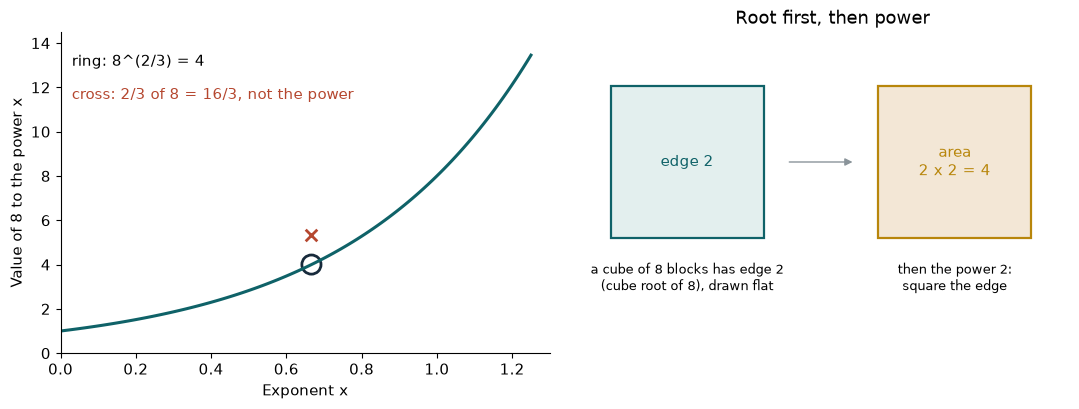

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))

xx = np.linspace(0, 1.25, 120)
a1.plot(xx, 8 ** xx, color=TEAL, linewidth=2.2)
e = 2 / 3
a1.scatter([e], [8 ** e], s=190, facecolors="none", edgecolors=NAVY, linewidths=2)
a1.scatter([e], [e * 8], marker="x", s=70, color=RED, linewidths=2)
a1.text(0.03, 13.5, "ring: 8^(2/3) = 4", va="top")
a1.text(0.03, 12, "cross: 2/3 of 8 = 16/3, not the power", va="top", color=RED)
a1.set_xlim(0, 1.3); a1.set_ylim(0, 14.5)
a1.set_xlabel("Exponent x"); a1.set_ylabel("Value of 8 to the power x")

# Steps drawn as lengths and areas: 8 as a cube of edge 2, then a square on that edge
a2.add_patch(plt.Rectangle((0.2, 0.5), 2, 2, facecolor="#e3efee", edgecolor=TEAL, linewidth=1.6))
a2.text(1.2, 1.5, "edge 2", ha="center", va="center", color=TEAL)
a2.text(1.2, 0.2, "a cube of 8 blocks has edge 2\n(cube root of 8), drawn flat", ha="center", va="top", fontsize=9)
a2.annotate("", xy=(3.4, 1.5), xytext=(2.5, 1.5), arrowprops=dict(arrowstyle="-|>", color=GREY))
a2.add_patch(plt.Rectangle((3.7, 0.5), 2, 2, facecolor="#f3e7d6", edgecolor=GOLD, linewidth=1.6))
a2.text(4.7, 1.5, "area\n2 x 2 = 4", ha="center", va="center", color=GOLD)
a2.text(4.7, 0.2, "then the power 2:\nsquare the edge", ha="center", va="top", fontsize=9)
a2.set_xlim(0, 6.2); a2.set_ylim(-1, 3.2); a2.set_aspect("equal")
a2.set_xticks([]); a2.set_yticks([])
for s in a2.spines.values():
    s.set_visible(False)
a2.set_title("Root first, then power")
finish(fig)

**What this shows.** For $8^{2/3}$ the denominator 3 asks for the cube root (2) and the numerator 2 asks for squaring (4). The curve shows $8^x$ at every exponent from 0 to 1.25; the ring marks the true power, and the cross marks the tempting wrong move of multiplying $\tfrac{2}{3}$ by 8.

**Where it stops working.** Positive bases only: a negative number has no real square root. Values that are not whole numbers (like $8^{1/2}$ or $4^{1/3}$) are shown to four decimals and are approximate; no terminating decimal is exact.

## 3. Second differences

**The question:** How can a table at equally spaced inputs reveal a quadratic pattern?

**The equations from the chapter:**

$$q(x) = 2x^2 + 1 \qquad\qquad ax^2 + bx + c$$

**What the symbols mean:** *First differences* subtract neighboring outputs. *Second differences* subtract neighboring first differences. For $ax^2 + bx + c$ at steps of 1, the second difference is $2a$.

Predict first: if the 2 in $2x^2 + 1$ becomes 3, what will every second difference be?

In [6]:
def table(a):
    ys = [a * x * x + 1 for x in range(5)]
    d1 = [ys[k + 1] - ys[k] for k in range(4)]
    d2 = [d1[k + 1] - d1[k] for k in range(3)]
    return ys, d1, d2

a = 2
ys, d1, d2 = table(a)
print(f"q(x) = {a}x^2 + 1")
print("  outputs:  " + ", ".join(f"q({x}) = {a}({x})^2 + 1 = {y}" for x, y in enumerate(ys)))
print("  first differences:  " + ", ".join(f"{ys[k + 1]} - {ys[k]} = {d1[k]}" for k in range(4)))
print("  second differences: " + ", ".join(f"{d1[k + 1]} - {d1[k]} = {d2[k]}" for k in range(3)))
print(f"  2a = 2 x {a} = {2 * a}, and every second difference is {2 * a}.")
print()
print("Other leading coefficients:")
for a in (1, 2, 3, 0):
    ys, d1, d2 = table(a)
    print(f"  a = {a}: outputs {ys}; first {d1}; second {d2}; 2a = 2 x {a} = {2 * a}")
print()
print("With a = 0 the rule is just 1: the outputs never change and the rule is not quadratic.")
print("Check q(x) = x^2 + 1: outputs 1, 2, 5, 10, 17; first 1, 3, 5, 7; second 2, 2, 2 = 2 x 1.")

q(x) = 2x^2 + 1
  outputs:  q(0) = 2(0)^2 + 1 = 1, q(1) = 2(1)^2 + 1 = 3, q(2) = 2(2)^2 + 1 = 9, q(3) = 2(3)^2 + 1 = 19, q(4) = 2(4)^2 + 1 = 33
  first differences:  3 - 1 = 2, 9 - 3 = 6, 19 - 9 = 10, 33 - 19 = 14
  second differences: 6 - 2 = 4, 10 - 6 = 4, 14 - 10 = 4
  2a = 2 x 2 = 4, and every second difference is 4.

Other leading coefficients:
  a = 1: outputs [1, 2, 5, 10, 17]; first [1, 3, 5, 7]; second [2, 2, 2]; 2a = 2 x 1 = 2
  a = 2: outputs [1, 3, 9, 19, 33]; first [2, 6, 10, 14]; second [4, 4, 4]; 2a = 2 x 2 = 4
  a = 3: outputs [1, 4, 13, 28, 49]; first [3, 9, 15, 21]; second [6, 6, 6]; 2a = 2 x 3 = 6
  a = 0: outputs [1, 1, 1, 1, 1]; first [0, 0, 0, 0]; second [0, 0, 0]; 2a = 2 x 0 = 0

With a = 0 the rule is just 1: the outputs never change and the rule is not quadratic.
Check q(x) = x^2 + 1: outputs 1, 2, 5, 10, 17; first 1, 3, 5, 7; second 2, 2, 2 = 2 x 1.


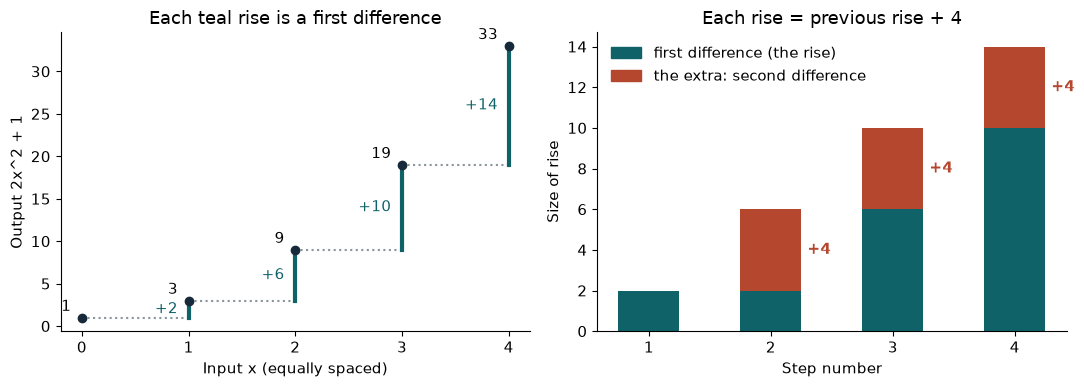

In [7]:
a = 2
ys, d1, d2 = table(a)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
xs = list(range(5))
a1.scatter(xs, ys, color=NAVY, zorder=4)
for k in range(4):
    a1.plot([k, k + 1], [ys[k], ys[k]], color=GREY, linestyle="dotted")
    a1.plot([k + 1, k + 1], [ys[k], ys[k + 1]], color=TEAL, linewidth=3)
    a1.text(k + 0.9, (ys[k] + ys[k + 1]) / 2, f"+{d1[k]}", ha="right", va="center", color=TEAL)
for x, y in zip(xs, ys):
    a1.text(x - 0.1, y + 0.8, str(y), ha="right")
a1.set_xticks(xs); a1.set_xlabel("Input x (equally spaced)"); a1.set_ylabel("Output 2x^2 + 1")
a1.set_title("Each teal rise is a first difference")

a2.bar(range(1, 5), d1, color=TEAL, width=0.5, label=None)
for k in range(1, 4):
    a2.bar(k + 1, d2[k - 1], bottom=d1[k - 1], width=0.5, color=RED)
    a2.text(k + 1.3, d1[k - 1] + d2[k - 1] / 2, f"+{d2[k - 1]}", color=RED, fontweight="bold", va="center")
a2.set_xticks(range(1, 5)); a2.set_xlabel("Step number"); a2.set_ylabel("Size of rise")
a2.set_title("Each rise = previous rise + 4")
from matplotlib.patches import Patch
a2.legend(handles=[Patch(color=TEAL, label="first difference (the rise)"),
                   Patch(color=RED, label="the extra: second difference")], frameon=False, loc="upper left")
finish(fig)

**What this shows.** The rises keep growing (2, 6, 10, 14), but they grow by the same amount each time: 4, which is $2a$. Constant, nonzero second differences at equal input steps fit a quadratic. Change $a$ to 3 and every second difference becomes $2 \times 3 = 6$.

**Where it stops working.** A finite table supports a pattern choice but cannot prove an unknown process follows the rule at inputs not listed. And the inputs must be equally spaced before differences mean anything.

## 4. Three families

**The question:** What separates a linear, a quadratic and an exponential pattern?

**The equations from the chapter:**

$$f(x) = 2x + 3 \qquad\qquad g(x) = x^2 \qquad\qquad h(x) = 2^x$$

**What the symbols mean:** A *difference* subtracts one output from the next. A *factor* divides the next output by the one before it. The inputs step by 1 from $-2$ to $2$.

Predict first: for $h(x) = 2^x$, which stays constant from step to step, the difference or the factor?

In [8]:
families = {
    "f(x) = 2x + 3": lambda x: Fraction(2 * x + 3),
    "g(x) = x^2": lambda x: Fraction(x * x),
    "h(x) = 2^x": lambda x: Fraction(2) ** x,
}
xs = [-2, -1, 0, 1, 2]

def fq(v):
    v = Fraction(v)
    return q(v) if v.denominator == 1 and v >= 0 else f"({q(v)})"

for name, rule in families.items():
    ys = [rule(x) for x in xs]
    print(name + ":  outputs at -2, -1, 0, 1, 2 are " + ", ".join(q(y) for y in ys))
    diffs = [f"{q(ys[k + 1])} - {par(ys[k])} = {q(ys[k + 1] - ys[k])}" for k in range(4)]
    print("  differences: " + "; ".join(diffs))
    facs = []
    for k in range(4):
        if ys[k] == 0:
            facs.append(f"{q(ys[k + 1])} / 0 is undefined")
        else:
            facs.append(f"{fq(ys[k + 1])} / {fq(ys[k])} = {q(ys[k + 1] / ys[k])}")
    print("  factors:     " + "; ".join(facs))
    dvals = {ys[k + 1] - ys[k] for k in range(4)}
    fvals = {ys[k + 1] / ys[k] for k in range(4) if ys[k] != 0}
    print(f"  constant difference? {len(dvals) == 1}    constant factor? {len(fvals) == 1 and all(ys[k] != 0 for k in range(4))}")
    print()
print("Check on f: the factor from x = 1 to 2 is 7/5, and from 0 to 1 it is 5/3. Different, so the factor is not constant; the difference 2 is.")

f(x) = 2x + 3:  outputs at -2, -1, 0, 1, 2 are -1, 1, 3, 5, 7
  differences: 1 - (-1) = 2; 3 - 1 = 2; 5 - 3 = 2; 7 - 5 = 2
  factors:     1 / (-1) = -1; 3 / 1 = 3; 5 / 3 = 5/3; 7 / 5 = 7/5
  constant difference? True    constant factor? False

g(x) = x^2:  outputs at -2, -1, 0, 1, 2 are 4, 1, 0, 1, 4
  differences: 1 - 4 = -3; 0 - 1 = -1; 1 - 0 = 1; 4 - 1 = 3
  factors:     1 / 4 = 1/4; 0 / 1 = 0; 1 / 0 is undefined; 4 / 1 = 4
  constant difference? False    constant factor? False

h(x) = 2^x:  outputs at -2, -1, 0, 1, 2 are 1/4, 1/2, 1, 2, 4
  differences: 1/2 - 1/4 = 1/4; 1 - 1/2 = 1/2; 2 - 1 = 1; 4 - 2 = 2
  factors:     (1/2) / (1/4) = 2; 1 / (1/2) = 2; 2 / 1 = 2; 4 / 2 = 2
  constant difference? False    constant factor? True

Check on f: the factor from x = 1 to 2 is 7/5, and from 0 to 1 it is 5/3. Different, so the factor is not constant; the difference 2 is.


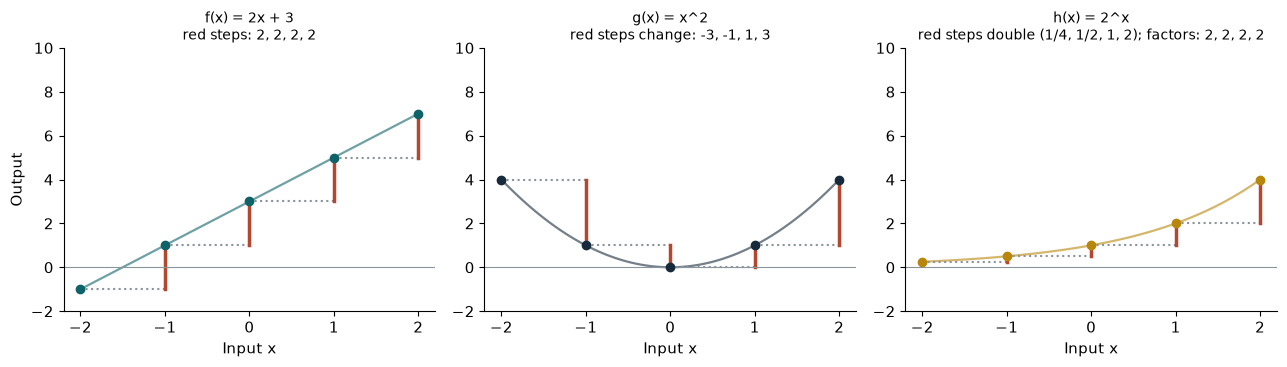

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
grid = np.linspace(-2, 2, 81)
curves = [("f(x) = 2x + 3", 2 * grid + 3, TEAL), ("g(x) = x^2", grid ** 2, NAVY), ("h(x) = 2^x", 2.0 ** grid, GOLD)]
notes = ["red steps: 2, 2, 2, 2", "red steps change: -3, -1, 1, 3", "red steps double (1/4, 1/2, 1, 2); factors: 2, 2, 2, 2"]
for ax, (name, curve, col), note in zip(axes, curves, notes):
    rule = families[name]
    ys = [float(rule(x)) for x in xs]
    ax.plot(grid, curve, color=col, linewidth=1.6, alpha=0.6)
    ax.scatter(xs, ys, color=col, zorder=4)
    for k in range(4):
        ax.plot([xs[k], xs[k + 1]], [ys[k], ys[k]], color=GREY, linestyle="dotted")
        ax.plot([xs[k + 1], xs[k + 1]], [ys[k], ys[k + 1]], color=RED, linewidth=2.5)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_title(name + "\n" + note, fontsize=10)
    ax.set_xticks(xs); ax.set_xlabel("Input x")
    ax.set_ylim(-2, 10)
axes[0].set_ylabel("Output")
finish(fig)

**What this shows.** The red segments are the differences between neighboring outputs. For $f$ they are the same every step (2), the mark of a linear pattern. For $g$ they change. For $h$ the differences change too (they double), but the *factor* is the same every step (2), the mark of an exponential pattern.

**Where it stops working.** Each function is defined for all real numbers; the table only samples five inputs. A factor is undefined when the earlier output is 0, as for $g(x) = x^2$ at $x = 0$.

## Practice

**1.** Is $y = x^2$ a function on the inputs $-1, 0, 1$?

<details><summary>Show answer</summary>

Yes. $-1$ goes to $(-1)^2 = 1$, $0$ goes to $0^2 = 0$, and $1$ goes to $1^2 = 1$. Each input has exactly one output; two inputs happen to share the output 1, which is allowed.

</details>

**2.** What is $4^{3/2}$?

<details><summary>Show answer</summary>

The denominator 2 asks for the square root: $\sqrt{4} = 2$. The numerator 3 asks for the cube of that: $2^3 = 8$. Check: $8^2 = 64$ and $4^3 = 64$.

</details>

**3.** For $q(x) = x^2 + 1$ at inputs 0 to 4, what are the outputs and the second differences?

<details><summary>Show answer</summary>

Outputs: $0^2 + 1 = 1$, $1^2 + 1 = 2$, $2^2 + 1 = 5$, $3^2 + 1 = 10$, $4^2 + 1 = 17$. First differences: $2 - 1 = 1$, $5 - 2 = 3$, $10 - 5 = 5$, $17 - 10 = 7$. Second differences: $3 - 1 = 2$, $5 - 3 = 2$, $7 - 5 = 2$, each equal to $2a = 2 \times 1 = 2$.

</details>